# Regression: audit, inference and held-out forecasting
**Owner:** Quoc Dat · **Protocol:** Rec.md §6 · **Seed:** 42.
The original exploratory cells are retained below. Full-sample EDA is descriptive;
all C3 inference, transformations, variable selection and model comparison use training batteries.
Test histories are used only as permitted by E1/E2. The main research model remains the multiple log-linear regression.
See `docs/Regression_Report.md` and `docs/Regression_SEM_Audit.md` for interpretation and limitations.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/cycles_clean.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start within this repository; processed cycles table not found')
sys.path.insert(0, str(PROJECT_ROOT/'src'))
from regression_sem_utils import load_cycles, regression_data, environment_manifest
np.random.seed(42)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
print('Project:', PROJECT_ROOT)
print('Versions:', environment_manifest()['packages'])

Project: C:\Users\Admin\OneDrive\Tài liệu\HK1-Nam 3\PTTK\Project\STAT3013.R11.CTTT_Group08
Versions: {'numpy': '2.4.6', 'pandas': '3.1.1', 'scipy': '1.17.1', 'matplotlib': '3.11.2', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.1', 'semopy': '2.3.11', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


Load the Cleaned Cycle-Level Dataset
Load cycles_clean.csv, the main processed dataset containing valid discharge cycles and their associated operating conditions, capacity measurements, and SOH values.


In [2]:
cycles = load_cycles()
print('Dataset shape:', cycles.shape)
cycles.head()

Dataset shape: (2658, 40)


,battery_id,group,op_index,cycle,cycle_valid,segment,start_time,ambient_C,I_level_A,profile,discharge_cutoff_V,capacity_Ah,capacity_to_2p7V_Ah,capacity_int_Ah,C0_Ah,soh_segment,soh,I_load_mean_A,V_min,duration_s,t_to_cutoff_s,energy_Wh,T_start_C,T_max_C,T_mean_C,chg_op_index,chg_duration_s,chg_end_time,chg_charge_Ah,chg_cc_time_s,chg_T_max_C,rest_before_h,n_chg_since_prev_dis,eis_op_index,Re_ohm,Rct_ohm,cap_outlier,break_in,long_rest,tier
0,B0005,G1,1,1,1,1,2008-04-02 15:25:41.593,24.0,2.0,constant_current,2.7,1.856487,1.856469,1.862016,1.851883,1.005472,1.005472,2.012621,2.612467,3690.234,3346.937,6.608164,24.330034,38.982181,32.572328,0.0,7597.875,2008-04-02 15:14:55.796,0.738393,667.891,27.445134,0.179388,1,NaN,NaN,NaN,False,False,False,A
1,B0005,G1,3,2,2,1,2008-04-02 19:43:48.406,24.0,2.0,constant_current,2.7,1.846327,1.846323,1.851883,1.851883,1.000000,1.000000,2.012561,2.587209,3672.344,3328.828,6.585710,24.697752,39.033398,32.725235,2.0,10516.000,2008-04-02 19:33:07.984,1.838209,3241.797,29.341949,0.177895,1,NaN,NaN,NaN,False,False,False,A
2,B0005,G1,5,3,3,1,2008-04-03 00:01:06.687,24.0,2.0,constant_current,2.7,1.835349,1.835336,1.840889,1.851883,0.994063,0.994063,2.012474,2.651917,3651.641,3309.422,6.555154,24.734266,38.818797,32.642862,4.0,10484.547,2008-04-02 23:50:25.359,1.832306,3238.719,29.553301,0.178147,1,NaN,NaN,NaN,False,False,False,A
3,B0005,G1,7,4,4,1,2008-04-03 04:16:37.375,24.0,2.0,constant_current,2.7,1.835263,1.835257,1.840781,1.851883,0.994005,0.994005,2.012181,2.592948,3631.563,3309.719,6.554398,24.654236,38.762305,32.514876,6.0,10397.890,2008-04-03 04:05:56.561,1.825609,3229.203,29.456340,0.178004,1,NaN,NaN,NaN,False,False,False,A
4,B0005,G1,9,5,5,1,2008-04-03 08:33:25.703,24.0,2.0,constant_current,2.7,1.834646,1.834635,1.840185,1.851883,0.993683,0.993683,2.012707,2.547420,3629.172,3307.688,6.551641,24.524797,38.665393,32.382349,8.0,10495.203,2008-04-03 08:22:44.328,1.823700,3228.218,29.481334,0.178160,1,NaN,NaN,NaN,False,False,False,A


Prepare the Regression Dataset
Filter the cleaned dataset to Tier A batteries and exclude capacity outliers and break-in cycles, following the project preprocessing rules for multiple log-linear regression.

In [3]:
regression_df = regression_data(cycles)
print('Regression rows:',len(regression_df),'batteries:',regression_df.battery_id.nunique())
regression_df.head()

Regression rows: 1475 batteries: 12


,battery_id,group,op_index,cycle,cycle_valid,segment,start_time,ambient_C,I_level_A,profile,discharge_cutoff_V,capacity_Ah,capacity_to_2p7V_Ah,capacity_int_Ah,C0_Ah,soh_segment,soh,I_load_mean_A,V_min,duration_s,t_to_cutoff_s,energy_Wh,T_start_C,T_max_C,T_mean_C,chg_op_index,chg_duration_s,chg_end_time,chg_charge_Ah,chg_cc_time_s,chg_T_max_C,rest_before_h,n_chg_since_prev_dis,eis_op_index,Re_ohm,Rct_ohm,cap_outlier,break_in,long_rest,tier,ln_soh
0,B0005,G1,1,1,1,1,2008-04-02 15:25:41.593,24.0,2.0,constant_current,2.7,1.856487,1.856469,1.862016,1.851883,1.005472,1.005472,2.012621,2.612467,3690.234,3346.937,6.608164,24.330034,38.982181,32.572328,0.0,7597.875,2008-04-02 15:14:55.796,0.738393,667.891,27.445134,0.179388,1,NaN,NaN,NaN,False,False,False,A,0.005457
1,B0005,G1,3,2,2,1,2008-04-02 19:43:48.406,24.0,2.0,constant_current,2.7,1.846327,1.846323,1.851883,1.851883,1.000000,1.000000,2.012561,2.587209,3672.344,3328.828,6.585710,24.697752,39.033398,32.725235,2.0,10516.000,2008-04-02 19:33:07.984,1.838209,3241.797,29.341949,0.177895,1,NaN,NaN,NaN,False,False,False,A,0.000000
2,B0005,G1,5,3,3,1,2008-04-03 00:01:06.687,24.0,2.0,constant_current,2.7,1.835349,1.835336,1.840889,1.851883,0.994063,0.994063,2.012474,2.651917,3651.641,3309.422,6.555154,24.734266,38.818797,32.642862,4.0,10484.547,2008-04-02 23:50:25.359,1.832306,3238.719,29.553301,0.178147,1,NaN,NaN,NaN,False,False,False,A,-0.005955
3,B0005,G1,7,4,4,1,2008-04-03 04:16:37.375,24.0,2.0,constant_current,2.7,1.835263,1.835257,1.840781,1.851883,0.994005,0.994005,2.012181,2.592948,3631.563,3309.719,6.554398,24.654236,38.762305,32.514876,6.0,10397.890,2008-04-03 04:05:56.561,1.825609,3229.203,29.456340,0.178004,1,NaN,NaN,NaN,False,False,False,A,-0.006013
4,B0005,G1,9,5,5,1,2008-04-03 08:33:25.703,24.0,2.0,constant_current,2.7,1.834646,1.834635,1.840185,1.851883,0.993683,0.993683,2.012707,2.547420,3629.172,3307.688,6.551641,24.524797,38.665393,32.382349,8.0,10495.203,2008-04-03 08:22:44.328,1.823700,3228.218,29.481334,0.178160,1,NaN,NaN,NaN,False,False,False,A,-0.006337


Select Variables for Regression Analysis
Extract the main identification, operating-condition, degradation, and SOH variables required for the regression analysis.

In [4]:
regression_columns = [
    "battery_id",
    "group",
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "profile",
    "capacity_int_Ah",
    "C0_Ah",
    "soh",
    "T_max_C",
    "long_rest",
]

regression_df[regression_columns].head(10)

,battery_id,group,cycle_valid,ambient_C,I_level_A,discharge_cutoff_V,profile,capacity_int_Ah,C0_Ah,soh,T_max_C,long_rest
0,B0005,G1,1,24.0,2.0,2.7,constant_current,1.862016,1.851883,1.005472,38.982181,False
1,B0005,G1,2,24.0,2.0,2.7,constant_current,1.851883,1.851883,1.000000,39.033398,False
2,B0005,G1,3,24.0,2.0,2.7,constant_current,1.840889,1.851883,0.994063,38.818797,False
3,B0005,G1,4,24.0,2.0,2.7,constant_current,1.840781,1.851883,0.994005,38.762305,False
4,B0005,G1,5,24.0,2.0,2.7,constant_current,1.840185,1.851883,0.993683,38.665393,False
5,B0005,G1,6,24.0,2.0,2.7,constant_current,1.841180,1.851883,0.994221,38.751695,False
6,B0005,G1,7,24.0,2.0,2.7,constant_current,1.840655,1.851883,0.993937,38.820701,False
7,B0005,G1,8,24.0,2.0,2.7,constant_current,1.831294,1.851883,0.988882,38.517130,False
8,B0005,G1,9,24.0,2.0,2.7,constant_current,1.830305,1.851883,0.988348,38.526268,False
9,B0005,G1,10,24.0,2.0,2.7,constant_current,1.830127,1.851883,0.988252,38.526981,False


Check Missing Values
Verify that the variables selected for regression contain no missing values before proceeding with statistical analysis and model fitting.


In [5]:
regression_df[regression_columns].isna().sum()

battery_id            0
group                 0
cycle_valid           0
ambient_C             0
I_level_A             0
discharge_cutoff_V    0
profile               0
capacity_int_Ah       0
C0_Ah                 0
soh                   0
T_max_C               0
long_rest             0
dtype: int64

Inspect Battery Operating Conditions
Summarize the temperature, discharge current, cutoff voltage, and discharge profile of each Tier A battery to understand the experimental conditions represented in the regression dataset.

In [6]:
battery_conditions = (
    regression_df[
        [
            "battery_id",
            "group",
            "ambient_C",
            "I_level_A",
            "discharge_cutoff_V",
            "profile",
        ]
    ]
    .drop_duplicates()
    .sort_values("battery_id")
)

battery_conditions

,battery_id,group,ambient_C,I_level_A,discharge_cutoff_V,profile
0,B0005,G1,24.0,2.0,2.7,constant_current
168,B0006,G1,24.0,2.0,2.5,constant_current
336,B0007,G1,24.0,2.0,2.2,constant_current
504,B0018,G1,24.0,2.0,2.5,constant_current
910,B0033,G4,24.0,4.0,2.0,constant_current
1100,B0034,G4,24.0,4.0,2.2,constant_current
2028,B0045,G7,4.0,1.0,2.0,constant_current
2097,B0046,G7,4.0,1.0,2.2,constant_current
2165,B0047,G7,4.0,1.0,2.5,constant_current
2233,B0048,G7,4.0,1.0,2.7,constant_current


Count Valid Cycles per Battery
Calculate the number of usable discharge cycles contributed by each battery after preprocessing and filtering.

In [7]:
battery_counts = (
    regression_df.groupby("battery_id")
    .size()
    .reset_index(name="n_cycles")
    .sort_values("battery_id")
)

battery_counts

,battery_id,n_cycles
0,B0005,167
1,B0006,166
2,B0007,167
3,B0018,132
4,B0033,178
5,B0034,194
6,B0045,67
7,B0046,68
8,B0047,68
9,B0048,68


Descriptive Statistics of Regression Variables
Summarize the distribution, central tendency, and variability of cycle number, operating conditions, capacity, SOH, and battery temperature.

In [8]:
summary_columns = [
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "capacity_int_Ah",
    "C0_Ah",
    "soh",
    "T_max_C",
]

regression_df[summary_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
cycle_valid,1475.0,72.870508,49.707805,1.000000,32.000000,63.000000,108.000000,196.000000
ambient_C,1475.0,17.613559,9.327442,4.000000,4.000000,24.000000,24.000000,24.000000
I_level_A,1475.0,2.320678,1.044245,1.000000,2.000000,2.000000,4.000000,4.000000
discharge_cutoff_V,1475.0,2.375254,0.247575,2.000000,2.200000,2.500000,2.500000,2.700000
capacity_int_Ah,1475.0,1.450186,0.252249,0.746121,1.269549,1.462644,1.615533,2.046695
C0_Ah,1475.0,1.706246,0.259296,1.030535,1.532278,1.796863,1.856590,2.036557
soh,1475.0,0.851485,0.085699,0.575568,0.799989,0.848826,0.915780,1.041322
T_max_C,1475.0,35.552503,15.946647,10.196290,16.311567,39.182874,51.022480,61.137160


Correlation Analysis of Key Variables
Compute the Pearson correlation matrix to examine the initial linear relationships among cycle number, operating conditions, maximum battery temperature, and SOH.


In [9]:
correlation_columns = [
    "cycle_valid",
    "ambient_C",
    "I_level_A",
    "discharge_cutoff_V",
    "T_max_C",
    "soh",
]

correlation_matrix = regression_df[correlation_columns].corr()

correlation_matrix

,cycle_valid,ambient_C,I_level_A,discharge_cutoff_V,T_max_C,soh
cycle_valid,1.000000,0.431510,0.389254,-0.165175,0.497716,-0.685037
ambient_C,0.431510,1.000000,0.587923,-0.227128,0.908645,-0.069305
I_level_A,0.389254,0.587923,1.000000,-0.511964,0.850962,0.128716
discharge_cutoff_V,-0.165175,-0.227128,-0.511964,1.000000,-0.455013,-0.069394
T_max_C,0.497716,0.908645,0.850962,-0.455013,1.000000,-0.031489
soh,-0.685037,-0.069305,0.128716,-0.069394,-0.031489,1.000000


SOH Degradation Curves by Battery
Visualize SOH against valid cycle number for each Tier A battery to compare degradation trajectories and identify differences in ageing rates across batteries.

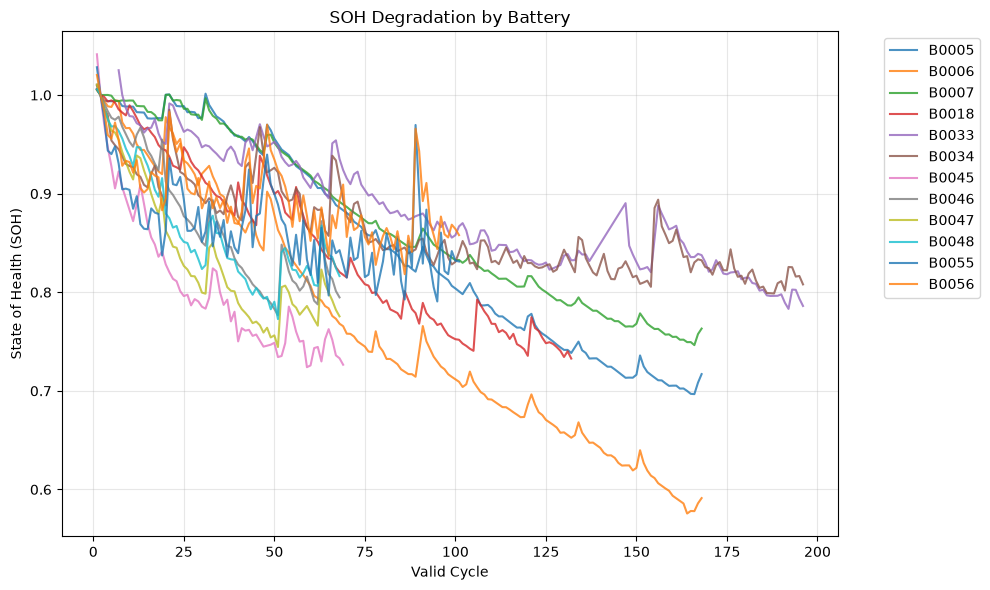

In [10]:
plt.figure(figsize=(10, 6))

for battery_id, battery_data in regression_df.groupby("battery_id"):
    plt.plot(
        battery_data["cycle_valid"],
        battery_data["soh"],
        label=battery_id,
        alpha=0.8,
    )

plt.xlabel("Valid Cycle")
plt.ylabel("State of Health (SOH)")
plt.title("SOH Degradation by Battery")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Correlation Between Cycle Number and SOH
Quantify the overall linear association between valid cycle number and SOH as an initial measure of battery degradation over repeated discharge cycles.

In [11]:
cycle_soh_corr = regression_df["cycle_valid"].corr(regression_df["soh"])

print(f"Correlation between cycle_valid and SOH: {cycle_soh_corr:.4f}")

Correlation between cycle_valid and SOH: -0.6850


## C3.1–C3.6: training inference and diagnostics
C3.2 uses **G1 training batteries** (B0005/B0006/B0018); B0007 remains held out.
Correlations include Re/Rct, discharge temperature and preceding-charge CC duration; same-cycle temperature is descriptive only.
VIF uses the actual fitted dummy/interaction matrix. The full research model retains all prespecified terms.
Four-step backward algorithm: fit the full model; test eligible terms; remove the largest p > 0.05; refit and repeat.
Hierarchy protects main effects. Clustered tests use small-sample correction and battery df; OLS selection is a sensitivity.
The course slide page 39 is absent from the repository: the exact slide wording still needs human verification.
Cluster inference with only three G1/eight training batteries and inference after selection are exploratory.
Functional-form R²/adjusted R² are response-scale-specific. SOH likelihood AIC/BIC for the log model includes the Jacobian.
Log predictions use a train-only Duan factor. HC3 uses t inference in the independent 23-battery comparison.

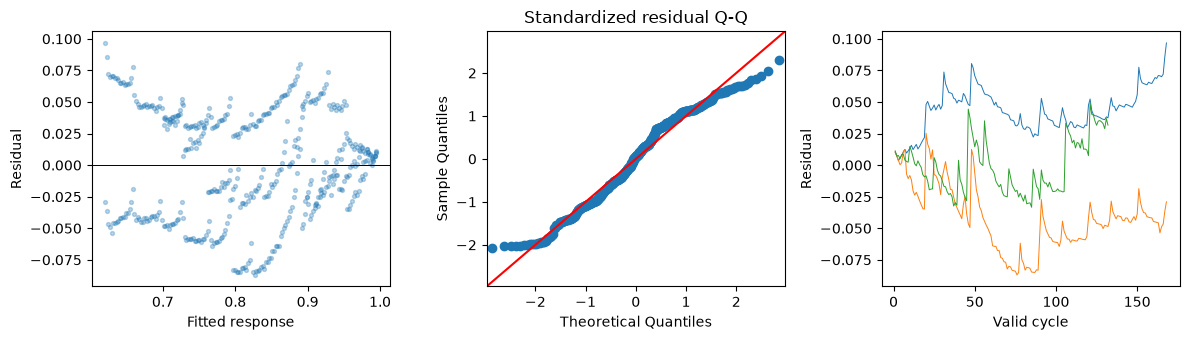

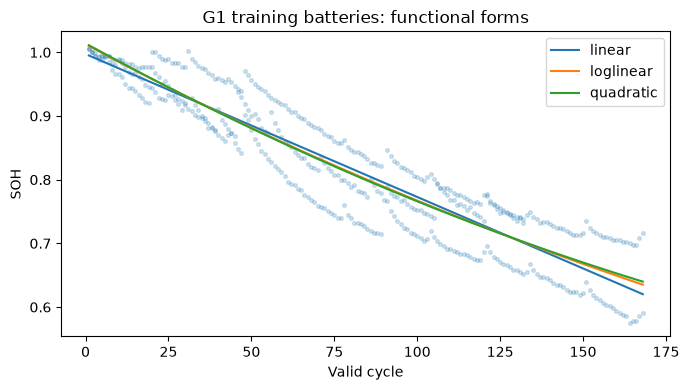

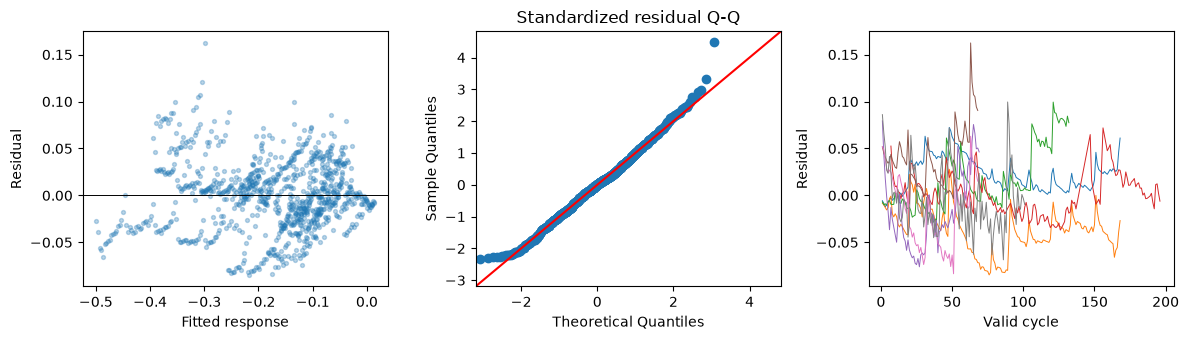

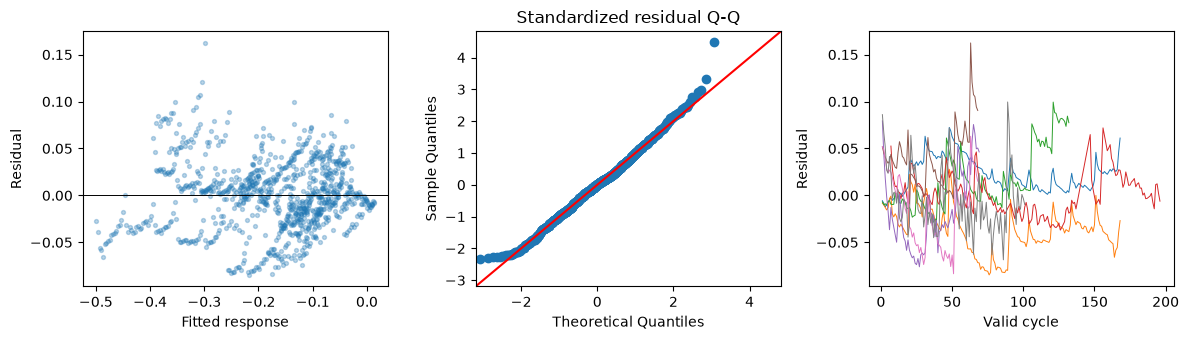

correlation_train


,variable,soh,cycle_valid,Re_ohm,Rct_ohm,T_max_C,chg_cc_time_s
0,soh,1.000000,-0.724614,0.094454,0.088709,-0.086879,0.333153
1,cycle_valid,-0.724614,1.000000,0.070991,-0.392065,0.505918,-0.036798
2,Re_ohm,0.094454,0.070991,1.000000,0.510722,-0.175556,-0.497135
3,Rct_ohm,0.088709,-0.392065,0.510722,1.000000,-0.811549,-0.880673
4,T_max_C,-0.086879,0.505918,-0.175556,-0.811549,1.000000,0.665519
5,chg_cc_time_s,0.333153,-0.036798,-0.497135,-0.880673,0.665519,1.000000


correlation_g1_train


,variable,soh,cycle_valid,Re_ohm,Rct_ohm,T_max_C,chg_cc_time_s
0,soh,1.000000,-0.928272,-0.746306,-0.789161,-0.707453,0.866443
1,cycle_valid,-0.928272,1.000000,0.468932,0.558709,0.733295,-0.842187
2,Re_ohm,-0.746306,0.468932,1.000000,0.953088,0.354654,-0.637506
3,Rct_ohm,-0.789161,0.558709,0.953088,1.000000,0.421095,-0.716143
4,T_max_C,-0.707453,0.733295,0.354654,0.421095,1.000000,-0.648817
5,chg_cc_time_s,0.866443,-0.842187,-0.637506,-0.716143,-0.648817,1.000000


simple_coefficients


,term,coefficient,OLS_SE,OLS_p,OLS_CI_low,OLS_CI_high,robust_type,robust_SE,robust_t,robust_p,robust_CI_low,robust_CI_high
0,Intercept,0.997255,0.003850,0.000000e+00,0.989689,1.004821,cluster,0.012241,81.465455,0.000151,0.944584,1.049926
1,cycle_valid,-0.002244,0.000042,5.127769e-201,-0.002326,-0.002162,cluster,0.000194,-11.551556,0.007411,-0.003080,-0.001408


... (26 outputs left out)

fade25_pct_per_100cyc


,term,coefficient,OLS_SE,OLS_p,OLS_CI_low,OLS_CI_high,robust_type,robust_SE,robust_t,robust_p,robust_CI_low,robust_CI_high
0,Intercept,103.594047,41.353804,0.021509,17.039540,190.148554,HC3,60.365700,1.716108,0.102403,-22.752815,229.940909
1,ambient_C,-0.095751,0.455737,0.835825,-1.049620,0.858118,HC3,0.441224,-0.217013,0.830511,-1.019243,0.827741
2,I_level_A,-9.686363,5.552863,0.097247,-21.308639,1.935912,HC3,6.230149,-1.554756,0.136504,-22.726216,3.353489
3,discharge_cutoff_V,-20.346519,15.767460,0.212391,-53.348193,12.655154,HC3,21.530297,-0.945018,0.356513,-65.409948,24.716910


fade_sample


,battery_id,group,tier,ambient_C,I_level_A,profile,discharge_cutoff_V,n_used,fade_pct_per_100cyc,n_used25,fade25_pct_per_100cyc,cycles_to_soh80,soh_last,T_max_med
0,B0005,G1,A,24.0,2.0,constant_current,2.7,167,20.965194,25,4.230354,102.0,0.716982,40.067325
1,B0006,G1,A,24.0,2.0,constant_current,2.5,166,24.699496,25,25.516642,61.0,0.591219,40.333019
2,B0007,G1,A,24.0,2.0,constant_current,2.2,167,16.998401,25,5.221523,126.0,0.763150,40.590429
3,B0018,G1,A,24.0,2.0,constant_current,2.5,132,20.959459,25,32.754664,77.0,0.732746,37.750585
4,B0025,G2,B,24.0,4.0,square_wave_0.05Hz,2.0,28,16.085210,25,15.157707,NaN,0.948371,41.187051
5,B0026,G2,B,24.0,4.0,square_wave_0.05Hz,2.2,25,10.494038,22,9.366215,NaN,0.966488,40.569844
6,B0027,G2,B,24.0,4.0,square_wave_0.05Hz,2.5,28,6.234080,25,4.644242,NaN,0.975095,42.658855
7,B0028,G2,B,24.0,2.0,square_wave_0.05Hz,2.7,28,14.625947,25,13.330415,NaN,0.951742,31.762320
8,B0029,G3,B,43.0,4.0,constant_current,2.0,39,30.931003,25,29.855637,NaN,0.883359,59.988217
9,B0030,G3,B,43.0,4.0,constant_current,2.2,39,30.379535,25,30.642285,NaN,0.885888,62.520660


In [12]:
from regression_analysis import chapter3
chapter = chapter3(regression_df)
for name, table in chapter.items():
    print(name)
    display(table)

## C3.7: forecasting, train-only GroupKFold(4) and EOL/RUL
Five prespecified regression candidates: full/selected log-linear, quadratic log-linear, history-anchored full and quadratic log-linear.
No test score selects a candidate. MAE is averaged equally across validation batteries; E1 and E2 are selected separately.
Direct forecasts use training smearing; anchored ratios cancel the common smearing factor and recalibrate the intercept using permitted history.
E1 anchor is the preceding retained observation. E2 anchor is frozen at the 60% origin; future SOH, EIS, charging or thermal values are never inputs.
All three conditions are validated across the complete Tier A series; E2 reads their origin values only.
Time-varying or missing conditions raise a feature-availability error. The retrospective clean-row schedule is fixed by team protocol.
The CSV label regression denotes scenario-specific strategies: E1 anchored_loglinear and E2 anchored_quadratic, with separate fitted coefficients.
Historical predictions are optional comparisons and never enter current fit, CV, metrics or exports.
The existing C0, centered Hampel flags and lifetime-based Tier A eligibility are **retrospective upstream constraints**;
this is not a prospective deployment validation. No preprocessing rule or original data is changed.
Only the first observed SOH ≤ 0.8 defines EOL. An event at/before origin is left-censored for this forecast task;
absence of a crossing is explicitly retained. RUL error requires both crossings inside the horizon.
Prediction intervals are unavailable and remain blank.

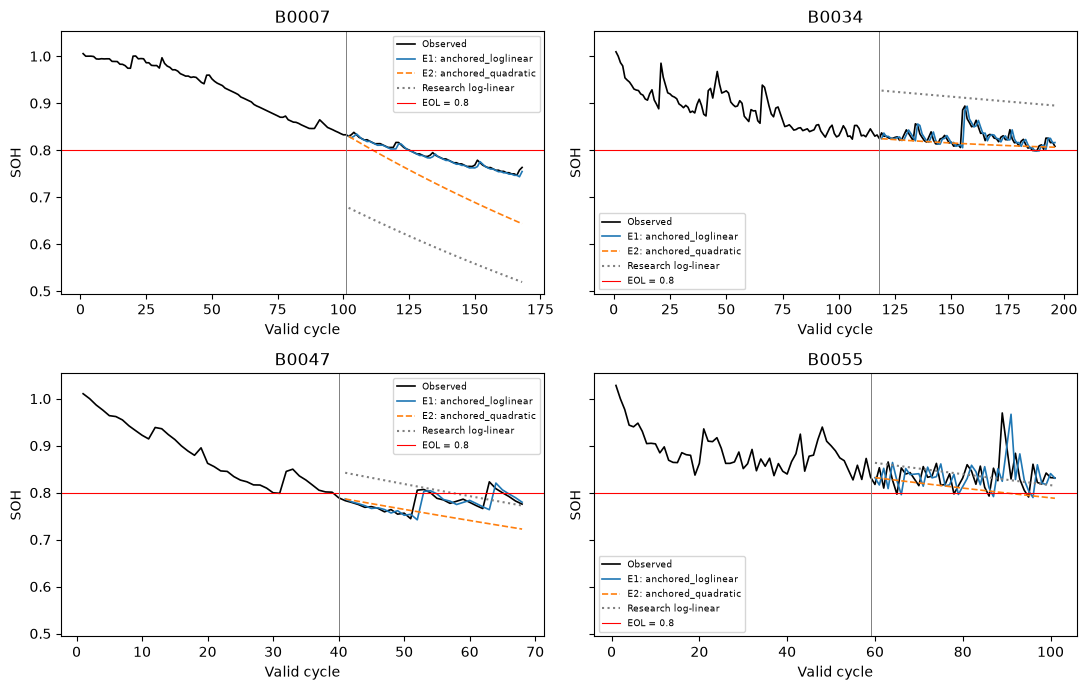

Frozen CV winners: {'E1': 'anchored_loglinear', 'E2': 'anchored_quadratic'}


,scenario,model,MAE
0,E1,anchored_loglinear,0.009470
1,E1,anchored_quadratic,0.009499
2,E1,quadratic_loglinear,0.070958
3,E1,research_loglinear,0.069690
4,E1,selected_loglinear,0.091151
5,E2,anchored_loglinear,0.035618
6,E2,anchored_quadratic,0.035370
7,E2,quadratic_loglinear,0.070958
8,E2,research_loglinear,0.069690
9,E2,selected_loglinear,0.091151


,model,scenario,battery_id,aggregation,n,MAE,RMSE,MAPE_pct,R2
0,anchored_loglinear,E1,B0007,battery,67,0.002576,0.004120,0.326711,0.972974
1,anchored_loglinear,E1,B0034,battery,78,0.008483,0.013479,1.013268,0.425551
2,anchored_loglinear,E1,B0047,battery,28,0.009143,0.017287,1.150550,0.066106
3,anchored_loglinear,E1,B0055,battery,40,0.034755,0.046051,4.101336,-1.285998
4,anchored_loglinear,E1,ALL,micro,213,0.011645,0.022570,1.395274,0.501072
...,...,...,...,...,...,...,...,...,...
79,selected_loglinear,E2,B0034,battery,78,0.083989,0.085763,10.200759,-22.255550
80,selected_loglinear,E2,B0047,battery,28,0.034380,0.042197,4.453278,-4.564325
81,selected_loglinear,E2,B0055,battery,40,0.024282,0.034458,2.876519,-0.279927
82,selected_loglinear,E2,ALL,micro,213,0.100546,0.122563,12.601862,-13.712831


,model,battery_id,origin_cycle,horizon_end,observed_EOL_cycle,predicted_EOL_cycle,status,observed_RUL,predicted_RUL,signed_RUL_error,absolute_RUL_error
0,anchored_loglinear,B0007,101,168,126.0,111.0,both_cross_within_horizon,25.0,10.0,-15.0,15.0
1,anchored_loglinear,B0034,118,196,186.0,185.0,both_cross_within_horizon,68.0,67.0,-1.0,1.0
2,anchored_loglinear,B0047,40,68,30.0,41.0,already_at_or_before_origin,NaN,NaN,NaN,NaN
3,anchored_loglinear,B0055,59,101,65.0,88.0,both_cross_within_horizon,6.0,29.0,23.0,23.0
4,anchored_quadratic,B0007,101,168,126.0,112.0,both_cross_within_horizon,25.0,11.0,-14.0,14.0
5,anchored_quadratic,B0034,118,196,186.0,NaN,prediction_no_crossing_in_horizon,68.0,NaN,NaN,NaN
6,anchored_quadratic,B0047,40,68,30.0,41.0,already_at_or_before_origin,NaN,NaN,NaN,NaN
7,anchored_quadratic,B0055,59,101,65.0,91.0,both_cross_within_horizon,6.0,32.0,26.0,26.0
8,persistence,B0007,101,168,126.0,NaN,prediction_no_crossing_in_horizon,25.0,NaN,NaN,NaN
9,persistence,B0034,118,196,186.0,NaN,prediction_no_crossing_in_horizon,68.0,NaN,NaN,NaN


In [13]:
from regression_analysis import evaluate_regression
forecast_results = evaluate_regression(regression_df)
print('Frozen CV winners:', forecast_results['winners'])
display(forecast_results['cv'])
display(forecast_results['test_metrics'])
display(forecast_results['eol'])

## C3.8: reporting and interpretation
Research coefficients describe conditional associations, not causes. A slope β changes predicted SOH by 100[exp(β)−1]% per valid cycle.
Interaction contrasts depend on reference temperature and centered current/cutoff. Incomplete crossing limits independent operating-condition claims.
Battery heterogeneity can shift the intercept on an unseen cell; anchoring uses observed history to reduce that discrepancy.
Quadratic terms diagnose nonlinearity but can extrapolate poorly. Pooled micro and equal-cell macro metrics are both exported;
negative per-cell R² can be large when the held-out tail has little variation. All candidate scores remain visible even if persistence wins.
The 23-cell fade outcome is itself an estimated slope; HC3 does not account for its first-stage estimation uncertainty.
Report-ready methods/results and the review checklist are in `docs/Regression_Report.md` and `docs/Regression_SEM_Audit.md`.